In [1]:
import fastf1 as f1
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math
import datetime
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, Normalizer, MinMaxScaler, LabelEncoder
from sklearn.metrics import mean_squared_error

f1.Cache.enable_cache("C:\\Users\davix\AppData\Local\Temp\FastF1_cache")

In [2]:
%load_ext tensorboard

FASE IMPORT DATI

In [2]:
df = pd.read_csv('F1_gp_tesi_official.csv')

In [8]:
df = df[df['Year'] == 2024]
df = df[['Round', 'Event']].drop_duplicates()

In [9]:
df

,Round,Event
119172,1,Sakhir
121430,2,Jeddah
122331,3,Melbourne
123329,4,Suzuka
124236,5,Shanghai
125268,6,Miami
126379,7,Imola
127617,8,Monaco
128854,9,Montréal
130126,10,Barcelona


In [7]:
df.count()

Unnamed: 0.3          119172
Unnamed: 0.2           93685
Unnamed: 0.1           70129
Unnamed: 0             45384
Time                  119172
Driver                119172
DriverNumber          119172
LapTime               115041
LapNumber             119172
Stint                 119172
PitOutTime              4026
PitInTime               4106
Sector1Time           119172
Sector2Time           119172
Sector3Time           119172
Sector1SessionTime    116356
Sector2SessionTime    118959
Sector3SessionTime    118836
SpeedI1               101810
SpeedI2               118914
SpeedFL               114844
SpeedST               109321
IsPersonalBest        119037
Compound              119133
TyreLife              119172
FreshTyre             119172
Team                  119172
LapStartTime          119172
LapStartDate          119037
TrackStatus           119149
Position              119172
Deleted               119172
DeletedReason           1084
FastF1Generated       119172
IsAccurate    

In [2]:
# power unit era df

df = pd.DataFrame()

In [3]:
ref_years = [2019, 2020, 2021, 2022, 2023, 2024]

for year in ref_years:
    race_list = f1.get_event_schedule(year)
    # escludo i test pre stagionali
    # race_list = race_list[2:]
    for race in race_list['Location']:
        print(year, race)
        session = f1.get_session(year, race , 'R')
        session.load(laps=True, telemetry=True)
        laps = session.laps
        event = session.event
        event_round = event['RoundNumber']
        
        try:
            weather = laps.get_weather_data()
            weather_data = weather.reset_index(drop=True)
        except:
            print('No meteo values')

        track_temp = weather_data['TrackTemp']
        track_rain = weather_data['Rainfall']
        track_air = weather_data['AirTemp']
        track_hum = weather_data['Humidity']
        track_windd = weather_data['WindDirection']
        track_winds = weather_data['WindSpeed']

        driver_list = pd.unique(session.laps['Driver'])

        for driver in driver_list:
            driver_race_session = laps.pick_drivers(driver)
            
            driver_race_session['TrackTemp'] = track_temp
            driver_race_session['Rainfall'] = track_rain
            driver_race_session['AirTemp'] = track_air
            driver_race_session['Humidity'] = track_hum
            driver_race_session['WindDirection'] = track_windd
            driver_race_session['WindSpeed'] = track_winds
            driver_race_session['Round'] = event_round.astype(str)
            driver_race_session['Event'] = race
        
            driver_race_session = driver_race_session.fillna({'Sector1Time': pd.Timedelta(0, 's'), 'Sector2Time': pd.Timedelta(0, 's') , 'Sector3Time': pd.Timedelta(0, 's'), 'Time': pd.Timedelta(0, 's')})
            driver_race_session = driver_race_session.fillna({'LapNumber': 0, 'Stint': 0, 'Position': 0})
                
            # aggiustamento delle colonne con tipo Time
            driver_race_session['Sector1Time'] = (driver_race_session['Sector1Time']/pd.Timedelta(1, 's')).astype(float)
            driver_race_session['Sector2Time'] = (driver_race_session['Sector2Time']/pd.Timedelta(1, 's')).astype(float)
            driver_race_session['Sector3Time'] = (driver_race_session['Sector3Time']/pd.Timedelta(1, 's')).astype(float)
            driver_race_session['Time'] = (driver_race_session['Time']/pd.Timedelta(1, 's')).astype(float)
            
            # aggiustamento delle colonne con tipo Integer
            driver_race_session['Stint'] = driver_race_session['Stint'].astype(int)
            driver_race_session['LapNumber'] = driver_race_session['LapNumber'].astype(int)
            driver_race_session['AirTemp'] = driver_race_session['AirTemp'].astype(float)
            driver_race_session['Humidity'] = driver_race_session['Humidity'].astype(float)
            driver_race_session['WindDirection'] = driver_race_session['WindDirection'].astype(float)
            driver_race_session['WindSpeed'] = driver_race_session['WindSpeed'].astype(float)
            
            # aggiustamento delle colonne con tipo String
            driver_race_session['TyreLife'] = driver_race_session['TyreLife'].astype(str)
            driver_race_session['Position'] = driver_race_session['Position'].astype(str)
            driver_race_session['DriverNumber'] = driver_race_session['DriverNumber'].astype(str)
            driver_race_session['TrackStatus'] = driver_race_session['TrackStatus'].astype(str)
            
            # conversioni/mapping
            driver_race_session['Driver'] = driver_race_session['Driver'].astype(str)
            driver_race_session['Rainfall'] = np.where(driver_race_session['Rainfall'] == True, 1, 0)
            
            driver_race_session['Year'] = year
            driver_race_session['Year'] = driver_race_session['Year'].astype(str)

            compound_mapping = {'HYPERSOFT': 1, 'ULTRASOFT': 1, 'SUPERSOFT': 1, 'SOFT': 1, 'MEDIUM': 2, 'HARD': 3, 'INTERMEDIATE': 4, 'WET': 5}
            driver_race_session['Compound'] = driver_race_session['Compound'].map(compound_mapping)
            driver_race_session = driver_race_session.drop_duplicates()
            
   
            if df.empty:
                df = driver_race_session
            else:
                df = pd.concat([df, driver_race_session])

core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.4.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info


2024 Sakhir


logger      WARNING 	Failed to load result data from Ergast!
core        WARNING 	No result data for this session available on Ergast! (This is expected for recent sessions)
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
logger      WARNING 	Failed to add first lap time from Ergast!
req            INFO 	Using cached data for car_data
req            INFO 	No cached data found for position_data. Loading data...
_api           INFO 	Fetching position data...
_api           INFO 	Parsing position data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for weather_data. Loading data...
_api           INFO 	Fetching weather data...
req            INF

C:\Users\davix\AppData\Local\Temp\ipykernel_14188\1419894070.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  driver_race_session['TrackTemp'] = track_temp
C:\Users\davix\AppData\Local\Temp\ipykernel_14188\1419894070.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  driver_race_session['Rainfall'] = track_rain
C:\Users\davix\AppData\Local\Temp\ipykernel_14188\1419894070.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_in

C:\Users\davix\AppData\Local\Temp\ipykernel_14188\1419894070.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  driver_race_session['TrackTemp'] = track_temp
C:\Users\davix\AppData\Local\Temp\ipykernel_14188\1419894070.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  driver_race_session['Rainfall'] = track_rain
C:\Users\davix\AppData\Local\Temp\ipykernel_14188\1419894070.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_in

req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info


... (110 outputs left out)

2024 Yas Island


req            INFO 	Data has been written to cache!
logger      WARNING 	Failed to load result data from Ergast!
core        WARNING 	No result data for this session available on Ergast! (This is expected for recent sessions)
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for _extended_timing_data. Loading data...
_api           INFO 	Fetching timing data...
_api           INFO 	Parsing timing data...
req            INFO 	Data has been written to cache

C:\Users\davix\AppData\Local\Temp\ipykernel_14188\1419894070.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  driver_race_session['TrackTemp'] = track_temp
C:\Users\davix\AppData\Local\Temp\ipykernel_14188\1419894070.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  driver_race_session['Rainfall'] = track_rain
C:\Users\davix\AppData\Local\Temp\ipykernel_14188\1419894070.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_in

C:\Users\davix\AppData\Local\Temp\ipykernel_14188\1419894070.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  driver_race_session['TrackTemp'] = track_temp
C:\Users\davix\AppData\Local\Temp\ipykernel_14188\1419894070.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  driver_race_session['Rainfall'] = track_rain
C:\Users\davix\AppData\Local\Temp\ipykernel_14188\1419894070.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_in

In [7]:
fields = ['LapNumber', 'Stint', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Time', 'TrackTemp', 'Round', 'DriverNumber', 'TyreLife', 'Position', 'TrackStatus','Rainfall', 'Year', 'Event', 'Compound']

df_t = df[fields]
df_t[df_t['Year'] == '2021'].isnull().sum()

LapNumber       0
Stint           0
Sector1Time     0
Sector2Time     0
Sector3Time     0
Time            0
TrackTemp       0
Round           0
DriverNumber    0
TyreLife        0
Position        0
TrackStatus     0
Rainfall        0
Year            0
Event           0
Compound        0
dtype: int64

In [7]:
df_t[(df_t['Compound'].isnull()) & (df_t['Year'] == '2021')]

,LapNumber,Stint,Sector1Time,Sector2Time,Sector3Time,Time,TrackTemp,Round,DriverNumber,TyreLife,Position,TrackStatus,Rainfall,Year,Event,Compound
6,1,1,0.000,96.890,53.917,15569.078,15.3,12,44,1.0,3.0,1,0,2021,Spa-Francorchamps,NaN
7,2,1,55.741,92.236,51.124,15768.219,15.3,12,44,2.0,3.0,1,1,2021,Spa-Francorchamps,NaN
8,3,1,53.382,91.206,60.572,15973.330,15.2,12,44,3.0,3.0,15,1,2021,Spa-Francorchamps,NaN
9,1,1,0.000,96.334,54.696,15570.973,15.3,12,3,1.0,4.0,1,0,2021,Spa-Francorchamps,NaN
10,2,1,55.219,91.923,52.045,15770.098,15.3,12,3,2.0,4.0,1,1,2021,Spa-Francorchamps,NaN
11,3,1,54.072,90.090,62.308,15976.574,15.2,12,3,3.0,4.0,15,1,2021,Spa-Francorchamps,NaN
12,1,1,0.000,97.122,55.188,15573.956,15.3,12,5,1.0,5.0,1,0,2021,Spa-Francorchamps,NaN
13,2,1,54.306,92.277,51.913,15772.479,15.3,12,5,2.0,5.0,1,1,2021,Spa-Francorchamps,NaN
14,3,1,52.916,91.267,64.298,15980.934,15.2,12,5,3.0,5.0,15,1,2021,Spa-Francorchamps,NaN
15,1,1,0.000,96.460,56.332,15576.654,15.3,12,10,1.0,6.0,1,0,2021,Spa-Francorchamps,NaN


In [5]:
df_2024 = df

In [8]:
df = pd.concat([df, df_2024])

In [ ]:
df.fillna('', inplace=True)

In [ ]:
s = f1.get_session(2023, 8, 'R')
s.load(laps=True, telemetry=True)

In [9]:
# df = df[df['Year'] != '2022']
df['Year'].unique()

array([2019, 2020, 2021, 2022, 2023, '2024'], dtype=object)

In [10]:
df[df['Year'] == '2021']['Round'].unique()

array(['1', '2'], dtype=object)

In [5]:
df_tmp = df[df['Year'] != '2022']

In [10]:
df.to_csv('F1_gp_tesi_official2.csv', index=True, encoding='utf-8')

FASE PULIZIA DATI

In [ ]:
# df_temp = df_final[df_final['DriverNumber'] == '44']
# df_temp = df_temp.sort_values(by=['Round', 'Stint'])
# df_temp = df_temp[(df_temp['Stint'] == 1) & (df_temp['Round'] == '5') & (df_temp['LapNumber'] == 1)]
# df_temp

In [44]:
df = df[df['Compound'].notnull()]
df.fillna('0', inplace=True)
df = df.drop_duplicates()

In [45]:
# aggiustamento delle colonne con tipo Time
df['Sector1Time'] = (df['Sector1Time']).astype(float)
df['Sector2Time'] = (df['Sector2Time']).astype(float)
df['Sector3Time'] = (df['Sector3Time']).astype(float)
df['Time'] = (df['Time']).astype(float)

# aggiustamento delle colonne con tipo Integer
df['Stint'] = df['Stint'].astype(int)
df['LapNumber'] = df['LapNumber'].astype(int)
df['Compound'] = df['Compound'].astype(int)
df['TrackTemp'] = df['TrackTemp'].astype(float)

# aggiustamento LapTime con tipo Float
df['tempo_td'] = pd.to_timedelta(df['LapTime'])
df['LapTime'] = df['tempo_td'].dt.total_seconds()
df = df.drop(columns=['tempo_td'])

# aggiustamento delle colonne con tipo String
df['TyreLife'] = df['TyreLife'].astype(str)
df['Position'] = df['Position'].astype(str)
df['DriverNumber'] = df['DriverNumber'].astype(str)
df['TrackStatus'] = df['TrackStatus'].astype(str)
df['Driver'] = df['Driver'].astype(str)
df['Year'] = df['Year'].astype(str)
df['Round'] = df['Round'].astype(str)

df_final = df.drop_duplicates()

In [14]:
df_final.to_csv('F1_gp_tesi_e22.csv', index=True, encoding='utf-8')

In [46]:
df_final['LapTime'].unique()

array([104.485, 129.434, 117.989, ...,  88.407,  83.769,  83.606])

In [6]:
df_final.count()

Unnamed: 0.3          131522
Unnamed: 0.2          131522
Unnamed: 0.1          131522
Unnamed: 0            131522
Time                  131522
Driver                131522
DriverNumber          131522
LapTime               131522
LapNumber             131522
Stint                 131522
PitOutTime            131522
PitInTime             131522
Sector1Time           131522
Sector2Time           131522
Sector3Time           131522
Sector1SessionTime    131522
Sector2SessionTime    131522
Sector3SessionTime    131522
SpeedI1               131522
SpeedI2               131522
SpeedFL               131522
SpeedST               131522
IsPersonalBest        131522
Compound              131522
TyreLife              131522
FreshTyre             131522
Team                  131522
LapStartTime          131522
LapStartDate          131522
TrackStatus           131522
Position              131522
Deleted               131522
DeletedReason         131522
FastF1Generated       131522
IsAccurate    

In [47]:
# filtri in base alle caratteristiche volute nel test
# tengo solo le piste dove non ha piovuto e quelle piste ad alto carico aerodinamico

# list_circuit = ['Melbourne', 'Jeddah', 'Budapest', 'Imola', 'Mexico City', 'Yas Island', 'São Paulo', 'Montréal', 'Marina Bay', 'Shanghai', 'Singapore', 'Suzuka', 'Zandvoort', 'Monte Carlo', 'Mugello', 'Sakhir', 'Monaco']
fields = ['LapNumber', 'LapTime', 'Time', 'TrackTemp', 'Round', 'DriverNumber', 'TyreLife', 'Position', 'TrackStatus','Rainfall', 'Year', 'Event', 'Stint', 'Compound']

df_final = df_final[(df_final['Rainfall'] == 0) ] # & (df_final['Event'].isin(list_circuit))
df_final = df_final[fields]

In [ ]:
# test raggruppando i dati per anno, gran premio, pilota e stint

df_groupie = df_final.groupby(['Year', 'Event', 'DriverNumber', 'Stint'])['LapNumber'].max().reset_index()

df_final = pd.merge(df_final, df_groupie, on=['Year', 'Event', 'DriverNumber', 'Stint', 'LapNumber'], how='inner')
df_final

In [48]:
df_final.drop('Event', axis=1, inplace=True)

df_final['tmp'] = df_final['Round'].str.cat(df_final['Year'], sep='|')
df_final_train = df_final[(df_final['tmp'] != '7|2023') & ((df_final['Compound'] != 4) & (df_final['Compound'] != 5))]
df_final_test = df_final[(df_final['Round'] == '7') & (df_final['Year'] == '2023')]

df_final_train.drop('tmp', axis=1, inplace=True)
df_final_test.drop('tmp', axis=1, inplace=True)
df_final.drop('tmp', axis=1, inplace=True)

C:\Users\davix\AppData\Local\Temp\ipykernel_20924\2524225549.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final_train.drop('tmp', axis=1, inplace=True)
C:\Users\davix\AppData\Local\Temp\ipykernel_20924\2524225549.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final_test.drop('tmp', axis=1, inplace=True)


In [63]:
df_final_test.groupby(['Stint'])['Compound'].value_counts()

Stint  Compound
1      1           214
       2            70
       3            16
2      3           246
       2           146
       1            70
3      3           282
       2           141
       1            67
4      2            45
       1            15
Name: Compound, dtype: int64

In [46]:
# frequenza gomme valori di training
freq_tr = pd.crosstab(index=df_final_train['Compound'],
                             columns=['Abs. frequence'],
                             colnames=[''])
freq_tr

,Abs. frequence
Compound,
1,36632
2,42383
3,40965


In [47]:
freq = pd.crosstab(index=df_final_test['Compound'],
                             columns=['Abs. frequence'],
                             colnames=[''])
freq

,Abs. frequence
Compound,
1,366
2,402
3,544


In [49]:
df_final_test

,LapNumber,LapTime,Time,TrackTemp,Round,DriverNumber,TyreLife,Position,TrackStatus,Rainfall,Year,Stint,Compound
90152,1,83.935,3820.152,33.4,7,1,1.0,1.0,1.0,0,2023,1,2
90153,2,80.402,3900.554,33.3,7,1,2.0,1.0,1.0,0,2023,1,2
90154,3,80.499,3981.053,33.0,7,1,3.0,1.0,1.0,0,2023,1,2
90155,4,80.346,4061.399,32.7,7,1,4.0,1.0,1.0,0,2023,1,2
90156,5,80.283,4141.682,32.6,7,1,5.0,1.0,1.0,0,2023,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
91459,61,81.280,8743.046,27.3,7,2,25.0,20.0,1.0,0,2023,3,3
91460,62,82.134,8825.180,27.2,7,2,26.0,20.0,1.0,0,2023,3,3
91461,63,80.420,8905.600,26.8,7,2,27.0,20.0,1.0,0,2023,3,3
91462,64,79.980,8985.580,27.1,7,2,28.0,20.0,1.0,0,2023,3,3


In [67]:
# LSTM/GRU prepare data vanilla

values = df_final.values
values = values.astype("float32")

# Normalizzare i dati
scaler = MinMaxScaler(feature_range = (0, 1))
df_scaled = scaler.fit_transform(values)

# prelevo la colonna da prevedere ( compound )
X = df_scaled[:, :-1]
y = df_scaled[:, -1]

# suddivido i dati tra test e addestramento 70% train e 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42)

train_X = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
test_X = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))
print(train_X.shape, y_train.shape, test_X.shape, y_test.shape)

(4405, 1, 14) (4405,) (1889, 1, 14) (1889,)


In [78]:
# LSTM/GRU preparo i dati per il database già diviso

values_train = df_final_train.values
values_test = df_final_test.values
values_train = values_train.astype("float32")
values_test = values_test.astype("float32")

# Normalizzare i dati
scaler = MinMaxScaler(feature_range = (0, 1))
df_scaled_train = scaler.fit_transform(values_train)
df_scaled_test = scaler.fit_transform(values_test)

# prelevo la colonna da prevedere ( stint, compound )
X_train = df_scaled_train[:, :-2]
X_test = df_scaled_test[:, :-2]
y_train = df_scaled_train[:, -2:]
y_test = df_scaled_test[:, -2:]

train_X = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
test_X = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))
print(train_X.shape, y_train.shape, test_X.shape, y_test.shape)

(119980, 1, 11) (119980, 2) (1312, 1, 11) (1312, 2)


In [31]:
# LSTM model
model = keras.Sequential()

model.add(layers.Input(shape=(train_X.shape[1], train_X.shape[2])))
model.add(layers.LSTM(128, activation = 'relu', return_sequences = True))
model.add(layers.Dropout(0.2))
model.add(layers.LSTM(128, activation = 'relu', return_sequences=True))
# model.add(layers.Dropout(0.2))
model.add(layers.LSTM(2, return_sequences=False))

In [79]:
# GRU model
model = keras.Sequential()

model.add(layers.Input(shape=(train_X.shape[1], train_X.shape[2])))
model.add(layers.GRU(128, activation = 'relu', return_sequences = True))
model.add(layers.Dropout(0.2))
model.add(layers.GRU(128, activation = 'relu', return_sequences=True))
model.add(layers.Dropout(0.2))
model.add(layers.GRU(128, activation = 'relu', return_sequences=True))
model.add(layers.GRU(2, return_sequences=False))

In [80]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru_12 (GRU)                         │ (None, 1, 128)              │          54,144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 1, 128)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_13 (GRU)                         │ (None, 1, 128)              │          99,072 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 1, 128)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_14 (GRU)                         │ (None, 1, 128)              │          99,072 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_15 (GRU)                         │ (None, 2)                   │             792 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 253,080 (988.59 KB)

 Trainable params: 253,080 (988.59 KB)

 Non-trainable params: 0 (0.00 B)

In [81]:
def run_experiment(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0005),
        loss='mean_squared_error',
        metrics=['accuracy'],
    )
    
    log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

    print("Start training the model...")
    history = model.fit(train_X, y_train, validation_data=(test_X, y_test), epochs=80, batch_size=50, shuffle = False, callbacks=[tensorboard_callback])
    print("Model training finished") 

    # accuratezza del modello
    test_loss, test_accuracy = model.evaluate(test_X, y_test)
    print(f'Test accuracy: {round(test_accuracy * 100, 2)}%')
    print(f'Test losses: {test_loss:.4f}')

In [82]:
# faccio previsioni
run_experiment(model) 
predictions = model.predict(test_X)

Start training the model...
Epoch 1/80
2400/2400 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.7677 - loss: 0.0489 - val_accuracy: 0.5793 - val_loss: 0.1141
Epoch 2/80
2400/2400 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.6647 - loss: 0.0497 - val_accuracy: 0.5899 - val_loss: 0.1836
Epoch 3/80
2400/2400 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.6631 - loss: 0.0499 - val_accuracy: 0.5732 - val_loss: 0.1881
Epoch 4/80
2400/2400 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.6539 - loss: 0.0502 - val_accuracy: 0.5709 - val_loss: 0.1860
Epoch 5/80
2400/2400 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.6653 - loss: 0.0508 - val_accuracy: 0.5716 - val_loss: 0.1842
Epoch 6/80
2400/2400 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.6206 - loss: 0.0489 - val_accuracy: 0.5694 - val_loss: 0.1766
Epoch 7/80
2400/2400 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.6880 - loss: 0.0462 - val_accuracy: 0.5671 - val_loss: 0.1730
Epoch 8/80
2400/2400 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step 

In [83]:
test_X

array([[[0.        , 0.19170654, 0.        , ..., 0.        ,
         0.        , 0.        ]],

       [[0.01538462, 0.10264671, 0.01526105, ..., 0.        ,
         0.        , 0.        ]],

       [[0.03076923, 0.10509193, 0.03054059, ..., 0.        ,
         0.        , 0.        ]],

       ...,

       [[0.95384616, 0.10310042, 0.96526927, ..., 0.        ,
         0.        , 0.        ]],

       [[0.9692308 , 0.09200919, 0.98045033, ..., 0.        ,
         0.        , 0.        ]],

       [[0.9846154 , 0.09891593, 0.9956834 , ..., 0.        ,
         0.        , 0.        ]]], dtype=float32)

In [86]:
X_te = test_X.reshape((test_X.shape[0], test_X.shape[2]))
final = np.concatenate((X_te, predictions), axis=1)
prediction = scaler.inverse_transform(final)
prediction = prediction[:, -2:].round(0).astype('int')
df_prediction = pd.DataFrame(prediction, columns=['Stint', 'Compound'])
df_prediction_group = df_prediction.groupby(['Stint', 'Compound']).size().reset_index(name='conteggio')
df_prediction_group

,Stint,Compound,conteggio
0,1,1,378
1,1,2,11
2,2,1,544
3,2,2,128
4,3,1,251


In [68]:
final = np.concatenate((X_te, y_test), axis=1)
original = scaler.inverse_transform(final)
original = original[:, -2:].round(0).astype('int')
df_original = pd.DataFrame(original, columns=['Stint', 'Compound'])
df_original_group = df_original.groupby(['Stint', 'Compound']).size().reset_index(name='conteggio')
df_original_group

,Stint,Compound,conteggio
0,1,1,214
1,1,2,70
2,1,3,16
3,2,1,70
4,2,2,146
5,2,3,246
6,3,1,67
7,3,2,141
8,3,3,282
9,4,1,15


array([[<AxesSubplot:title={'center':'Stint'}>,
        <AxesSubplot:title={'center':'Compound'}>],
       [<AxesSubplot:title={'center':'conteggio'}>, <AxesSubplot:>]],
      dtype=object)

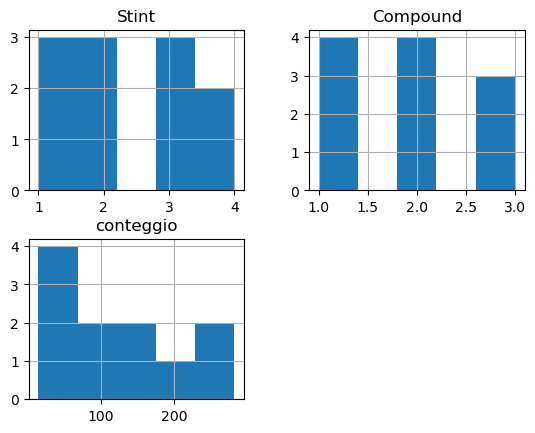

In [70]:
df_original_group.hist(bins=5)

<Figure size 1500x500 with 0 Axes>

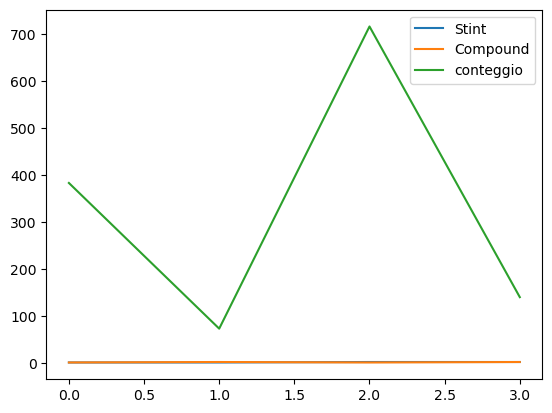

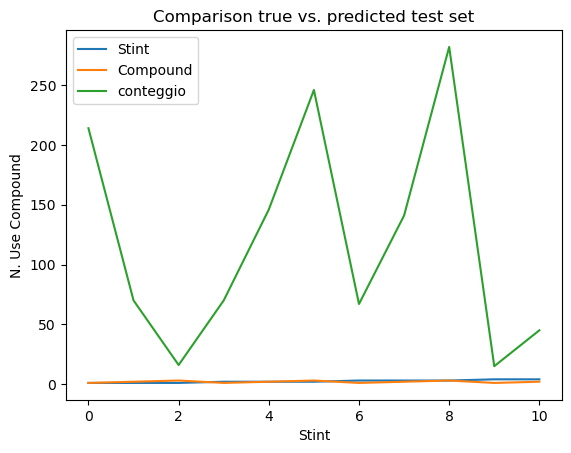

In [69]:
plt.figure(figsize = (15, 5))
df_prediction_group.plot(label="Predicted stint value")
df_original_group.plot(label="Test value")
plt.xlabel("Stint")
plt.ylabel("N. Use Compound")
plt.title("Comparison true vs. predicted test set")
plt.legend()
plt.show()

In [ ]:
%tensorboard --logdir logs/fit

[[1.0000000e+00 8.3934998e+01 3.8201523e+03 ... 2.0230000e+03
  1.0654764e+00 9.7510999e-01]
 [2.0000000e+00 8.0401993e+01 3.9005540e+03 ... 2.0230000e+03
  1.0616426e+00 9.7842860e-01]
 [3.0000000e+00 8.0499001e+01 3.9810530e+03 ... 2.0230000e+03
  1.0552400e+00 9.8465163e-01]
 ...
 [6.3000000e+01 8.0419998e+01 8.9055996e+03 ... 2.0230000e+03
  2.1990547e+00 1.0000070e+00]
 [6.4000000e+01 7.9980003e+01 8.9855801e+03 ... 2.0230000e+03
  2.1221433e+00 1.0000260e+00]
 [6.5000000e+01 8.0253998e+01 9.0658340e+03 ... 2.0230000e+03
  2.0240214e+00 1.0001581e+00]]
Year    Round  Stint   
2023.0  7.0    0.968017     13
               0.968536     14
               0.969590     15
               0.970008     12
               0.970628     18
                          ... 
               2.976263    128
               2.984911    131
               3.014349    261
               3.018530    130
               3.038026    129
Name: LapTime, Length: 1312, dtype: int64
Empty DataFrame
Columns: [Sti

F:\Anaconda\programma\lib\site-packages\pandas\core\reshape\merge.py:1207: UserWarning: You are merging on int and float columns where the float values are not equal to their int representation.
  warnings.warn(
F:\Anaconda\programma\lib\site-packages\pandas\core\reshape\merge.py:1207: UserWarning: You are merging on int and float columns where the float values are not equal to their int representation.
  warnings.warn(


<Figure size 1500x500 with 0 Axes>

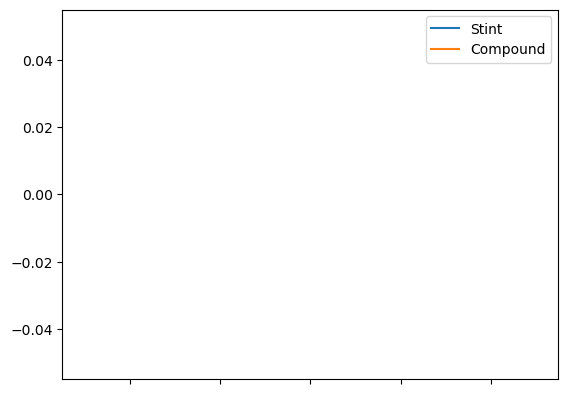

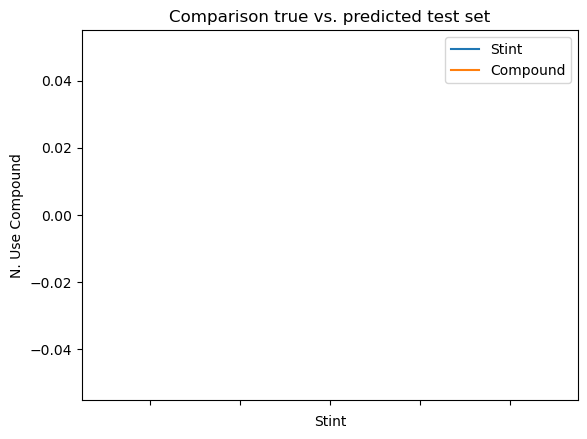

In [69]:
# LSTM/GRU show data

# riunisco campi di predizione e campi predetti per lo scaling
X_te = test_X.reshape((test_X.shape[0], test_X.shape[2]))
# invert scaling for forecast
pred = np.concatenate((X_te, predictions), axis=1)
pred_for = scaler.inverse_transform(pred)
print(pred_for)
# pred_for_compound = pred_for[:, -2:].astype('int')
# print(pred_for_compound)
pred_new = pd.DataFrame(pred_for, columns=['LapNumber', 'LapTime', 'Time', 'TrackTemp', 'Round', 'DriverNumber', 'TyreLife', 'Position', 'TrackStatus','Rainfall', 'Year', 'Stint', 'Compound'])
pred_new['Compound'] = pred_new['Compound']+1
to_maintain = ['Year', 'Round', 'Stint', 'LapTime']
df_pred_for_compound = pred_new[to_maintain]
pred_for_compound = df_pred_for_compound.groupby(['Year', 'Round', 'Stint'])['LapTime'].idxmin()#.unstack(fill_value=0)
print(pred_for_compound)
df_to_show = pd.merge(pred_new, pred_for_compound, on=['Year', 'Round', 'Stint', 'LapTime'], how='inner')
to_maintain = ['Stint', 'Compound']
df_to_show = df_to_show[to_maintain]
# df_pred_for_compound['Stint'] = df_pred_for_compound['Stint']+1
print(df_to_show)

X_tr = train_X.reshape((train_X.shape[0], train_X.shape[2]))
Y_tr = y_train.reshape((train_X.shape[0], 2))
# invert scaling for actual
orig = np.concatenate((X_tr, Y_tr), axis=1)
# print(orig.shape)
orig_to = scaler.inverse_transform(orig)
orig_to_compound = orig_to[:, -2:].astype('int')

to_maintain = ['Year', 'Round', 'Stint', 'LapTime']
df_data = df_final_test[to_maintain]
data = df_data.groupby(['Year', 'Round', 'Stint'])['LapTime'].idxmin()#.unstack(fill_value=0)
df_to_show_orig = pd.merge(df_final_test, data, on=['Year', 'Round', 'Stint', 'LapTime'], how='inner')
to_maintain = ['Stint', 'Compound']
df_to_show_orig = df_to_show_orig[to_maintain]
print(df_to_show_orig)

# val_unique_stint_pred, count_stint_pred = np.unique(pred_for_compound[0], return_counts=True)
# val_unique_comp_pred, count_comp_pred = np.unique(pred_for_compound[1], return_counts=True)
# val_unique_orig, count_orig = np.unique(orig_to_compound, return_counts=True)
# val_unique_stint_dataset, count_stint_dataset = np.unique(data[0], return_counts=True)
# val_unique_comp_dataset, count_comp_dataset = np.unique(data[1], return_counts=True)

# val_unique_comp_pred += 1
# print(val_unique_stint_pred, count_stint_pred)
# print(val_unique_comp_pred, count_comp_pred)
# print(val_unique_stint_dataset, count_stint_dataset)
# print(val_unique_comp_dataset, count_comp_dataset)

plt.figure(figsize = (15, 5))
df_to_show.plot( label="Predicted stint value")
df_to_show_orig.plot(label="Test value")
plt.xlabel("Stint")
plt.ylabel("N. Use Compound")
plt.title("Comparison true vs. predicted test set")
plt.legend()
plt.show()

In [ ]:
# LSTM show data original

# riunisco campi di predizione e campi predetti per lo scaling
X_te = test_X.reshape((test_X.shape[0], test_X.shape[2]))
# invert scaling for forecast
pred = np.concatenate((X_te, predictions), axis=1)
print(pred.shape)
pred_for = scaler.inverse_transform(pred)
pred_for_compound = pred_for[:,-1].astype('int')
print(pred_for_compound)

X_tr = train_X.reshape((train_X.shape[0], train_X.shape[2]))
Y_tr = y_train.reshape((train_X.shape[0], 1))
# invert scaling for actual
orig = np.concatenate((X_tr, Y_tr), axis=1)
# print(orig.shape)
orig_to = scaler.inverse_transform(orig)
orig_to_compound = orig_to[:,-1].astype('int')

X_dataset = test_X.reshape((test_X.shape[0], test_X.shape[2]))
Y_dataset = y_test.reshape((test_X.shape[0], 1))
# invert scaling for forecast
data = np.concatenate((X_dataset, Y_dataset), axis=1)
# print(data.shape)
data = scaler.inverse_transform(data)
data = data[:,-1].astype('int')

val_unique_pred, count_pred = np.unique(pred_for_compound, return_counts=True)
val_unique_orig, count_orig = np.unique(orig_to_compound, return_counts=True)
val_unique_dataset, count_dataset = np.unique(data, return_counts=True)

val_unique_pred += 1
print(val_unique_pred, count_pred)
print(val_unique_dataset, count_dataset)

plt.figure(figsize = (15, 5))
plt.bar(val_unique_dataset, count_dataset, label="Test value")
plt.bar(val_unique_pred, count_pred, label="Predicted value")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Comparison true vs. predicted test set")
plt.legend()
plt.show()

In [ ]:
plt.plot(val_unique_pred)
plt.show()

In [ ]:
# Calculate RMSE.
score = math.sqrt(mean_squared_error(y_test, pred_for_compound))

# print("Training data score: %.2f RMSE" % rmse_train)
print("Test data score: %.2f RMSE" % score)

In [ ]:
X = test_X.reshape((test_X.shape[0], test_X.shape[2]))
Y = y_test.reshape((y_test.shape[0], 1))
temp = np.concatenate((X, Y), axis=1)
temp = scaler.inverse_transform(temp)
orig = temp[:,-1].astype('int')

In [ ]:
df = pd.DataFrame(pred_for_compound)
df[0].unique()

In [ ]:
freq = pd.crosstab(index=df[0],
                             columns=['Abs. frequence'],
                             colnames=[''])
freq

In [11]:
f1.Cache.clear_cache()

In [10]:
f1.Cache.get_cache_info()

('C:\\Users\\davix\\AppData\\Local\\Temp\\FastF1_cache', 285773824)

In [ ]:
def create_model_inputs():
    inputs = {}
    for field in X.columns:
        if field in numeric_features or field in binary_features:
            inputs[field] = layers.Input(
                name=field, shape=(), dtype="float64"
            )
        else:
            inputs[field] = layers.Input(
                name=field, shape=(), dtype="string"
            ) 
    print(inputs)    
    return inputs

In [ ]:
def encode_inputs(inputs, use_embedding=False):
    encoded_features = []
    for feature_name in inputs:
        if feature_name in categorical_features:
            vocabulary = categorical_features_dict[feature_name]
            # Create a lookup to convert string values to an integer indices.
            # Since we are not using a mask token nor expecting any out of vocabulary
            # (oov) token, we set mask_token to None and  num_oov_indices to 0.
            print(vocabulary)
            lookup = layers.StringLookup(
                vocabulary=vocabulary,
                mask_token=None,
                num_oov_indices=0,
                output_mode="int" if use_embedding else "binary",
            )
            if use_embedding:
                # Convert the string input values into integer indices.
                encoded_feature = lookup(inputs[feature_name])
                embedding_dims = int(math.sqrt(len(vocabulary)))
                # Create an embedding layer with the specified dimensions.
                embedding = layers.Embedding(
                    input_dim=len(vocabulary), output_dim=embedding_dims
                )
                # Convert the index values to embedding representations.
                encoded_feature = embedding(encoded_feature)
            else:
                # Convert the string input values into a one hot encoding.
                encoded_feature = lookup(
                    keras.ops.expand_dims(inputs[feature_name], -1)
                )
        else:
            # Use the numerical features as-is.
            encoded_feature = keras.ops.expand_dims(inputs[feature_name], -1)

        encoded_features.append(encoded_feature)

    all_features = layers.concatenate(encoded_features)
    return all_features

In [ ]:
def create_model():
    inputs = create_model_inputs()
    features = encode_inputs(inputs)

    for units in hidden_units:
        features = layers.Dense(units)(features)
        features = layers.BatchNormalization()(features)
        features = layers.ReLU()(features)
        features = layers.Dropout(0.1)(features)

    outputs = layers.Dense(13, activation="softmax")(features)
    model = keras.Model(inputs=inputs, outputs=outputs)
    return model


In [ ]:

# creo il modello
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),  # numero di features
    layers.RNN(keras.layers.SimpleRNNCell(4)),  # primo strato nascosto
    layers.RNN(keras.layers.SimpleRNNCell(4)),  # secondo strato nascosto
    layers.RNN(keras.layers.SimpleRNNCell(4)),  # secondo strato nascosto
    layers.RNN(keras.layers.SimpleRNNCell(4))  # strato di output (modifica per la regressione)
])

# compilazione del modello
model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
              loss='mean_squared_error',  # modificare il loss per la regressione
              metrics=['accuracy'])

In [ ]:
numeric_features = ['LapNumber', 'Stint', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Time', 'TrackTemp']
            
categorical_features = ['Round', 'DriverNumber', 'Compound', 'TyreLife', 'Position', 'TrackStatus', 'Driver']
categorical_features_dict = {
    "Round": list(df_final["Round"].unique()),
    "DriverNumber": list(df_final["DriverNumber"].unique()),
    "Compound": list(df_final["Compound"].unique()),
    "TyreLife": list(df_final["TyreLife"].unique()),
    "Position": list(df_final["Position"].unique()),
    "TrackStatus": list(df_final["TrackStatus"].unique())
}
            
binary_features = ['Rainfall']